# 02 - Return Prediction

Can trained models rank future returners better than simple behavioral rules? Compare rules and full-feature models, remove feature groups, try a small tuning search, and evaluate the validation choice on a later period.

In [1]:
from pathlib import Path
import sys

project_dir = Path.cwd()
if not (project_dir / "src" / "data_pipeline.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

## Build and check the cohort

In [2]:
from src.data_pipeline import run_pipeline

run_pipeline()

Saved 991,833 eligible users to data/processed/retention_cohort.parquet
Returned during days 15-44: 34,340 (3.5%)


In [3]:
import pandas as pd

cohort_path = project_dir / "data" / "processed" / "retention_cohort.parquet"
cohort = pd.read_parquet(cohort_path).sort_values("first_event_time").reset_index(drop=True)
cohort.head()

,user_id,first_event_time,events_first_14_days,active_days_first_14_days,high_intent_actions_first_14_days,days_since_last_event,events_days_7_13,events_per_active_day,longest_inactivity_gap_days,active_weeks_first_14_days,cart_actions_first_14_days,transactions_first_14_days,returned_days_15_44
0,693516,2015-05-03 03:00:04.384000+00:00,3,1,2,13.99971,0,3.0,13.99971,1,2,0,0
1,829044,2015-05-03 03:00:11.289000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
2,652699,2015-05-03 03:00:13.048000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
3,1125936,2015-05-03 03:00:24.154000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
4,1149227,2015-05-03 03:00:27.031000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0


In [4]:
from src.train_model import ALL_FEATURES, FEATURE_SETS, FEATURE_GROUPS, TARGET, _split_cohort
assert cohort["user_id"].is_unique
assert cohort[ALL_FEATURES].notna().all().all()
assert cohort[TARGET].notna().all()
assert set(cohort[TARGET].unique()).issubset({0, 1})

print(f"Cohort: {len(cohort):,} visitors")
print(cohort[TARGET].value_counts().rename(index={0: "no return", 1: "returned"}))
print(f"Return rate: {cohort[TARGET].mean():.1%}")
train, validation, _, _ = _split_cohort(cohort)

# Inspect feature-outcome relationships in training data only.
train.groupby(TARGET)[ALL_FEATURES].mean().T.rename(
    columns={0: "No return", 1: "Returned"}
)

Cohort: 991,833 visitors
returned_days_15_44
no return    957493
returned      34340
Name: count, dtype: int64
Return rate: 3.5%


returned_days_15_44,No return,Returned
events_first_14_days,1.815079,5.714625
active_days_first_14_days,1.102716,1.813837
cart_actions_first_14_days,0.041728,0.228200
transactions_first_14_days,0.012350,0.104592
days_since_last_event,13.629638,11.170383
events_per_active_day,1.560742,2.214751
events_days_7_13,0.055055,1.699612
longest_inactivity_gap_days,13.742118,12.241167
active_weeks_first_14_days,1.021489,1.212561
high_intent_actions_first_14_days,0.054077,0.332791


## Features

Feature summaries use training visitors only. All features use events before day 14. We group them as volume, activity patterns, intent, and recency. Cart and transaction counts stay separate; their combined count is used only as a simple ranking rule.

| Feature | Meaning at day 14 |
| --- | --- |
| Event count | Total recorded events. |
| Active days | Distinct UTC dates with activity. |
| Cart actions and transactions | Separate event counts. |
| Days since last event | Fractional days from the last event to day 14. |
| Events in days 7-13 | Events from 7 elapsed days up to, but excluding, day 14. |
| Events per active day | Event count divided by active UTC dates. |
| Longest inactivity gap | Longest gap between events, including the time from the last event to day 14. |
| Active weeks | Activity in one or both seven-day blocks: days 0-6 and 7-13. |

A rolling 14-day window can touch 15 UTC dates. Correlated features are kept. Combined intent equals cart plus transaction counts, so models use only the separate counts.

In [5]:
train[ALL_FEATURES].describe()

,events_first_14_days,active_days_first_14_days,cart_actions_first_14_days,transactions_first_14_days,days_since_last_event,events_per_active_day,events_days_7_13,longest_inactivity_gap_days,active_weeks_first_14_days,high_intent_actions_first_14_days
count,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000
mean,1.998844,1.136228,0.050515,0.016697,13.513746,1.591562,0.132555,13.671386,1.030493,0.067212
std,7.189532,0.577764,0.729867,0.426707,1.982874,2.011523,3.790169,1.285362,0.171940,1.091032
min,1.000000,1.000000,0.000000,0.000000,0.000006,1.000000,0.000000,0.977762,1.000000,0.000000
25%,1.000000,1.000000,0.000000,0.000000,13.999456,1.000000,0.000000,13.999456,1.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,14.000000,1.000000,0.000000,14.000000,1.000000,0.000000
75%,2.000000,1.000000,0.000000,0.000000,14.000000,1.500000,0.000000,14.000000,1.000000,0.000000
max,1152.000000,15.000000,93.000000,61.000000,14.000000,128.000000,945.000000,14.000000,2.000000,152.000000


## Evaluation setup

Average precision (AP) selects the ranking. Capture at 5%, 10%, and 20% measures the share of returners found at each selection size. All candidates use the same dates.

Training outcomes must be complete by July 3, 2015. Validation scoring runs July 3-7; its outcomes are complete by August 8, when holdout scoring begins. All dates use UTC. Waiting for outcomes limits the length of each evaluation period.

## Simple rules and full models

Compare sorting by event count, active days, high-intent count, and recency with logistic regression and XGBoost using all features. The recency rule puts the most recently active visitors first.

In [6]:
from src.train_model import (
    RULES, _rule_scores, _make_model, _ranking_metrics,
)

for name, rows in [("Training", train), ("Validation", validation)]:
    if rows.empty or rows[TARGET].nunique() < 2:
        raise ValueError(f"{name} data needs both outcomes.")

validation_predictions = _rule_scores(validation)
validation_predictions.insert(0, "returned", validation[TARGET].to_numpy())
candidates = {}
metrics = {
    name: _ranking_metrics(validation[TARGET], validation_predictions[name])
    for name in RULES
}


def compare_candidate(label, model_name, feature_set, params=None):
    columns = FEATURE_SETS[feature_set]
    model = _make_model(model_name, params)
    model.fit(train[columns], train[TARGET])
    predictions = model.predict_proba(validation[columns])[:, 1]
    validation_predictions[label] = predictions
    metrics[label] = _ranking_metrics(validation[TARGET], predictions)
    candidates[label] = {
        "model": model_name, "feature_set": feature_set, "params": dict(params or {}),
    }


for model_name in ("logistic regression", "XGBoost"):
    compare_candidate(f"{model_name} / full", model_name, "full")

full_model_names = list(candidates)
print(f"Training visitors: {len(train):,}; validation visitors: {len(validation):,}")
print(f"Validation return rate: {validation[TARGET].mean():.1%}")
pd.DataFrame(metrics).T.style.format("{:.5f}")

Training visitors: 169,613; validation visitors: 46,854
Validation return rate: 3.6%


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
event count,0.06874,0.15178,0.22732,0.08220,0.36324
active days,0.07808,0.19106,0.27374,0.09898,0.35442
high intent,0.04022,0.07920,0.12767,0.04616,0.22458
recency,0.09841,0.21133,0.30460,0.11014,0.39728
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
XGBoost / full,0.11666,0.20979,0.30712,0.11105,0.40007


## Remove one feature group at a time

Take the model with higher full-feature validation AP and refit it without each group, keeping its settings fixed.

Remove overlapping derived features too: events per active day with volume or patterns; late-week count with volume or recency; active weeks and longest gap with patterns or recency. Related information can still remain in other groups.

The AP change measures the group's added value for this model and setup, not causal importance.

In [7]:
ablation_model_label = max(full_model_names, key=lambda name: metrics[name]["average_precision"])
ablation_model = candidates[ablation_model_label]["model"]
full_ap = metrics[ablation_model_label]["average_precision"]
ablation_rows = {"full": {**metrics[ablation_model_label], "AP change vs full": 0.0}}

for group in FEATURE_GROUPS:
    feature_set = f"without {group}"
    label = f"{ablation_model} / {feature_set}"
    compare_candidate(label, ablation_model, feature_set)
    ablation_rows[feature_set] = {
        **metrics[label], "AP change vs full": metrics[label]["average_precision"] - full_ap,
    }

print(f"Group comparisons use: {ablation_model}")
pd.DataFrame(ablation_rows).T.style.format("{:.5f}")

Group comparisons use: XGBoost


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct,AP change vs full
full,0.11666,0.20979,0.30712,0.11105,0.40007,0.00000
without activity volume,0.11469,0.21022,0.30388,0.10988,0.39996,-0.00197
without activity patterns,0.11255,0.20866,0.30510,0.11032,0.40017,-0.00411
without intent,0.11595,0.21143,0.30665,0.11088,0.40003,-0.00071
without recency,0.09239,0.18958,0.29576,0.10694,0.39348,-0.02427


## Small tuning search

For each algorithm, use its best feature set tested above. Try two regularization values for logistic regression and three XGBoost changes: shallower trees, deeper trees, or more trees. The original settings remain eligible.

Choose among all rules and model trials using validation AP.

In [8]:
settings_to_try = {
    "logistic regression": [{"C": 0.1}, {"C": 10.0}],
    "XGBoost": [{"max_depth": 2}, {"max_depth": 4}, {"n_estimators": 200}],
}
# Choose feature sets before tuning either algorithm.
best_before_tuning = {}
for model_name in settings_to_try:
    names = [name for name, spec in candidates.items() if spec["model"] == model_name]
    best_before_tuning[model_name] = max(names, key=lambda name: metrics[name]["average_precision"])

tuning_rows = {}
for model_name, settings in settings_to_try.items():
    original = best_before_tuning[model_name]
    feature_set = candidates[original]["feature_set"]
    tuning_rows[original] = metrics[original]
    for params in settings:
        setting_name = ", ".join(f"{key}={value}" for key, value in params.items())
        label = f"{model_name} / {feature_set} / {setting_name}"
        compare_candidate(label, model_name, feature_set, params)
        tuning_rows[label] = metrics[label]

pd.DataFrame(tuning_rows).T.style.format("{:.5f}")

,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=0.1,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=10.0,0.11181,0.21429,0.29870,0.10800,0.40142
XGBoost / full,0.11666,0.20979,0.30712,0.11105,0.40007
XGBoost / full / max_depth=2,0.11616,0.21437,0.30573,0.11055,0.40089
XGBoost / full / max_depth=4,0.11660,0.20777,0.30704,0.11102,0.40143
XGBoost / full / n_estimators=200,0.11696,0.20890,0.30678,0.11092,0.40363


## Validation gains

Compare the four rules with the best tested version of each algorithm. The left panel shows 0-20% selected; the right shows the full curve. The diagonal represents random selection.

At a cutoff, visitor counts are rounded down, with at least one visitor selected. Tied scores are averaged. The chart table uses the same counts as the metric tables.

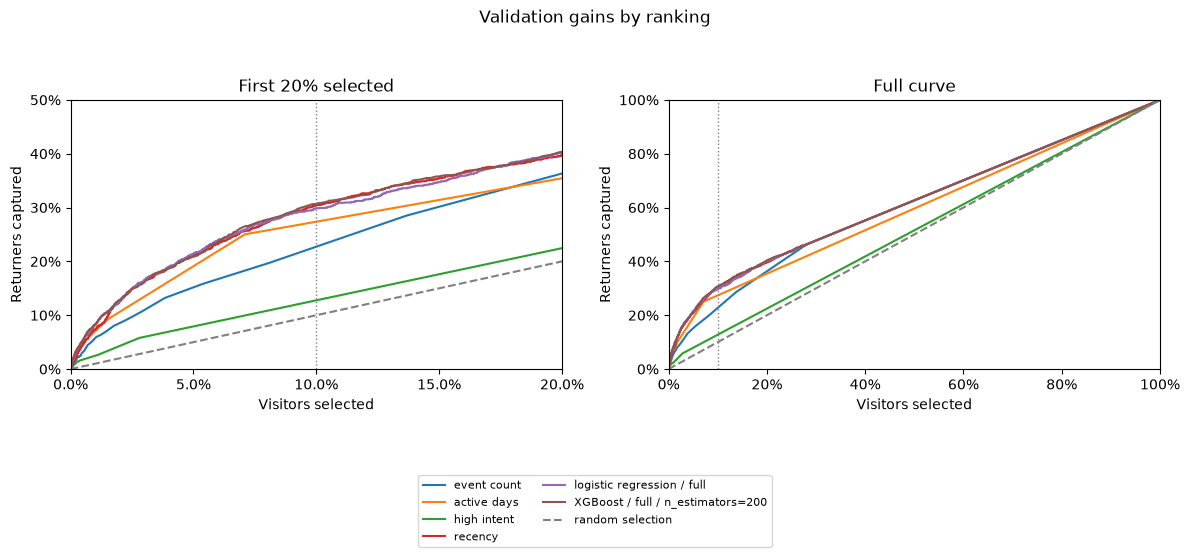

,event count,active days,high intent,recency,logistic regression / full,XGBoost / full / n_estimators=200
Top 5%,15.2%,19.1%,7.9%,21.1%,21.4%,20.9%
Top 10%,22.7%,27.4%,12.8%,30.5%,29.9%,30.7%
Top 20%,36.3%,35.4%,22.5%,39.7%,40.1%,40.4%


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


def plot_gains(scores, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    capture_at_capacity = {}
    for name in scores.columns.drop("returned"):
        # Group equal scores so their row order cannot affect the curve.
        groups = scores.groupby(name)["returned"].agg(["size", "sum"])
        groups = groups.sort_index(ascending=False)
        selected = np.r_[0, groups["size"].cumsum().to_numpy() / len(scores)]
        captured = np.r_[0, groups["sum"].cumsum().to_numpy() / scores["returned"].sum()]
        for ax in axes:
            ax.plot(selected, captured, label=name)
        # Match the rounded-down visitor counts used in the metric tables.
        counts = np.maximum(1, (np.array([0.05, 0.10, 0.20]) * len(scores)).astype(int))
        capture_at_capacity[name] = np.interp(counts / len(scores), selected, captured)

    for ax in axes:
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="random selection")
        ax.axvline(0.10, color="gray", linestyle=":", linewidth=1)
        ax.set(xlabel="Visitors selected", ylabel="Returners captured")
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.yaxis.set_major_formatter(PercentFormatter(1))

    zoom_top = max(values[-1] for values in capture_at_capacity.values())
    zoom_top = min(1, np.ceil((zoom_top + 0.02) * 10) / 10)
    axes[0].set(xlim=(0, 0.20), ylim=(0, zoom_top), title="First 20% selected")
    axes[0].set_xticks([0, 0.05, 0.10, 0.15, 0.20])
    axes[1].set(xlim=(0, 1), ylim=(0, 1), title="Full curve")
    fig.suptitle(title)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8)
    fig.tight_layout(rect=(0, 0.22, 1, 0.94))
    plt.show()
    return pd.DataFrame(capture_at_capacity, index=["Top 5%", "Top 10%", "Top 20%"]).style.format("{:.1%}")


# Plot each simple rule and the best tested version of each algorithm.
validation_metrics = pd.DataFrame(metrics).T
chart_names = list(RULES)
for model_name in ("logistic regression", "XGBoost"):
    names = [name for name, spec in candidates.items() if spec["model"] == model_name]
    chart_names.append(validation_metrics.loc[names, "average_precision"].idxmax())
plot_gains(validation_predictions[["returned", *chart_names]], "Validation gains by ranking")

## Choose the final approach

XGBoost with all features and 200 trees had the highest validation AP: 0.11734. Logistic regression reached 0.11181; recency was the strongest simple rule at 0.09841.

The 200-tree model is selected by validation AP. Its gain over the original XGBoost settings is small: 0.00053.

In [10]:
selected_name = validation_metrics["average_precision"].idxmax()
if selected_name in RULES:
    selected_model, selected_feature_set, selected_params = selected_name, "full", {}
else:
    chosen = candidates[selected_name]
    selected_model = chosen["model"]
    selected_feature_set = chosen["feature_set"]
    selected_params = dict(chosen["params"])

print(f"Chosen by validation AP: {selected_name}")
print(f"Features: {selected_feature_set}; settings: {selected_params or 'defaults'}")
validation_metrics.sort_values("average_precision", ascending=False).style.format("{:.5f}")

Chosen by validation AP: XGBoost / full / n_estimators=200
Features: full; settings: {'n_estimators': 200}


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
XGBoost / full / n_estimators=200,0.11696,0.20890,0.30678,0.11092,0.40363
XGBoost / full,0.11666,0.20979,0.30712,0.11105,0.40007
XGBoost / full / max_depth=4,0.11660,0.20777,0.30704,0.11102,0.40143
XGBoost / full / max_depth=2,0.11616,0.21437,0.30573,0.11055,0.40089
XGBoost / without intent,0.11595,0.21143,0.30665,0.11088,0.40003
XGBoost / without activity volume,0.11469,0.21022,0.30388,0.10988,0.39996
XGBoost / without activity patterns,0.11255,0.20866,0.30510,0.11032,0.40017
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=0.1,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=10.0,0.11181,0.21429,0.29870,0.10800,0.40142


## Save validation scores for notebook 03

Save the chosen ranking's validation scores and observed returns. Notebook 03 uses them to form score groups and reference return rates. This step does not run the holdout.

In [ ]:
validation_export = validation[["user_id", "first_event_time"]].reset_index(drop=True).copy()
validation_export["returned"] = validation[TARGET].to_numpy()
validation_export["score"] = validation_predictions[selected_name].to_numpy()
validation_export["ranking"] = selected_name

export_path = project_dir / "data" / "processed" / "validation_scores.parquet"
validation_export.to_parquet(export_path, index=False)
print("Saved validation scores to data/processed/validation_scores.parquet")

## Additional holdout evaluation

Refit the chosen model with its selected features and settings, using labels available by August 8. Compare it with the four rules on the later period.

This holdout was inspected during earlier work. It provides an additional chronological evaluation, not an untouched test.

In [11]:
from src.evaluate_holdout import evaluate_holdout

results = evaluate_holdout(cohort, selected_model, selected_feature_set, selected_params)
print(f"Chosen model: {results['selected_model']}; features: {results['feature_set']}")
print(f"Settings: {results['params'] or 'defaults'}")
print(f"Final training visitors: {results['final_train_users']:,}")
print(f"Holdout visitors: {results['test_users']:,}; return rate: {results['return_rate']:.1%}")
results["metrics"].style.format("{:.5f}")

Chosen model: XGBoost; features: full
Settings: {'n_estimators': 200}
Final training visitors: 538,406
Holdout visitors: 114,973; return rate: 2.7%


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
event count,0.05413,0.14609,0.23347,0.06313,0.37624
active days,0.07250,0.21775,0.28715,0.07765,0.36635
high intent,0.03005,0.07277,0.12158,0.03288,0.21918
recency,0.08690,0.23512,0.31071,0.08402,0.40495
XGBoost / full,0.10304,0.23770,0.30791,0.08326,0.40867


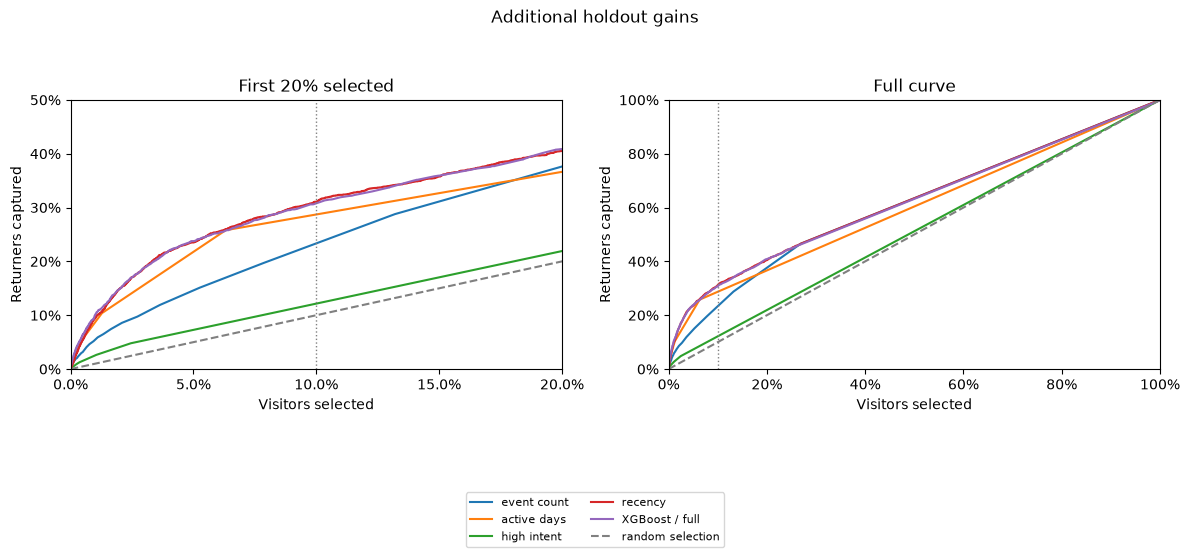

,event count,active days,high intent,recency,XGBoost / full
Top 5%,14.6%,21.8%,7.3%,23.5%,23.8%
Top 10%,23.3%,28.7%,12.2%,31.1%,30.8%
Top 20%,37.6%,36.6%,21.9%,40.5%,40.9%


In [12]:
plot_gains(results["holdout_scores"], "Additional holdout gains")

## Interpretation

Removing recency and its related features lowered XGBoost validation AP from 0.11681 to 0.09239, the largest drop in the group comparisons. Removing intent had little effect: AP fell to 0.11604.

On the later holdout, the selected XGBoost model achieved AP of 0.10299 versus 0.08690 for recency alone. At 10% selected, recency captured 31.1% of returners versus 31.0% for XGBoost. XGBoost was slightly ahead at 5% and 20%.

The model improves overall ranking, but simple recency sorting is competitive at these selection sizes. These results cover a short period and do not identify the best campaign audience: measuring additional returns caused by outreach requires a randomized experiment.